# 0.0 Introduzione

In questo progetto utilizzerò un estratto del famoso dataset ***Titanic – Machine Learning from Disaster***. 

Questo dataset è il punto di partenza canonico per chi vuole cimentarsi con i modelli supervisionati. Nasce dalla famosa competizione Kaggle lanciata nel 2012 e contiene i dati anagrafici, socio-economici e di viaggio dei passeggeri e membri d’equipaggio del RMS Titanic, affondato nella notte fra il 14 e il 15 aprile 1912. Lo scopo, didattico più che applicativo, è predire chi sia sopravvissuto al naufragio.

# 1.0 Import delle librerie

In [153]:
import pandas as pd
import numpy as np
from typing import Any, Optional
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

#pandas options
pd.options.display.max_rows = 30
pd.options.display.max_columns = 30

# riproducibilità di eventuali operazioni random
SEED: int = 0
np.random.seed(SEED)           

# 2.0 Lettura del Dataset

In [154]:
DATA_DIR = Path.cwd()
FILEPATH = DATA_DIR / "titanic_sub.csv"

df_raw: pd.DataFrame = pd.read_csv(
    FILEPATH,
    low_memory=False,
    na_values=["", "NA", "n/a"]
)
print(f"Loaded: {df_raw.shape[0]:,} righe × {df_raw.shape[1]} colonne")

Loaded: 891 righe × 6 colonne


In [155]:
df_raw.head(10)

,PassengerId,Sex,Age,Pclass,Embarked,Survived
0,1,male,22.0,3,S,0
1,2,female,38.0,1,C,1
2,3,female,26.0,3,S,1
3,4,female,35.0,1,S,1
4,5,male,35.0,3,S,0
5,6,male,NaN,3,Q,0
6,7,male,54.0,1,S,0
7,8,male,2.0,3,S,0
8,9,female,27.0,3,S,1
9,10,female,14.0,2,C,1


In [156]:
# Datatypes & non-null values
df_raw.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Sex          891 non-null    object 
 2   Age          714 non-null    float64
 3   Pclass       891 non-null    int64  
 4   Embarked     889 non-null    object 
 5   Survived     891 non-null    int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 41.9+ KB


In [157]:
# Descriptive statistics (numerical and categorical)
df_raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0


# 3.0 EDA

In [158]:
df_clean = df_raw.copy()

## 3.1 Duplicati?

In [159]:
print("Duplicated rows:", df_clean.duplicated().sum())

Duplicated rows: 0


## 3.2 Missing Values

In [160]:
def report_missing_values(
    df: pd.DataFrame,
    *,
    top_n: Optional[int] = 10,
    show_heatmap: bool = True,
    figsize: tuple[int, int] = (12, 6),
) -> pd.Series:
    """
    Analyze and visualize missing values in a DataFrame.
    
    Parameters
    ----------
    df : pd.DataFrame
        The DataFrame to analyze.
    top_n : int | None, default 10
        Number of columns to show in the percentage ranking (None → all).
    show_heatmap : bool, default True
        If True, draws a heatmap of the missing cells.
    figsize : tuple[int, int], default (12, 6)
        Figure size for the heatmap.
    
    Returns
    -------
    pd.Series
        Series with the count of NaNs per column (only those with at least
        one missing value), sorted in descending order.
    """
    """"""
    # 1. Conteggio dei NaN
    missing_counts = df.isna().sum()
    missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

    print("Missing values per column:")
    print(missing_counts, "\n")

    # 2. Percentuali di NaN
    missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
    if top_n is not None:
        display(missing_pct.head(top_n))
    else:
        display(missing_pct)

    # 3. Heatmap opzionale
    if show_heatmap:
        plt.figure(figsize=figsize)
        sns.heatmap(df.isna(), cbar=False, yticklabels=False)
        plt.title("Map of missing values")
        plt.show()

    return missing_counts

Missing values per column:
Age         177
Embarked      2
dtype: int64 



Age            19.865320
Embarked        0.224467
PassengerId     0.000000
Sex             0.000000
Pclass          0.000000
Survived        0.000000
dtype: float64

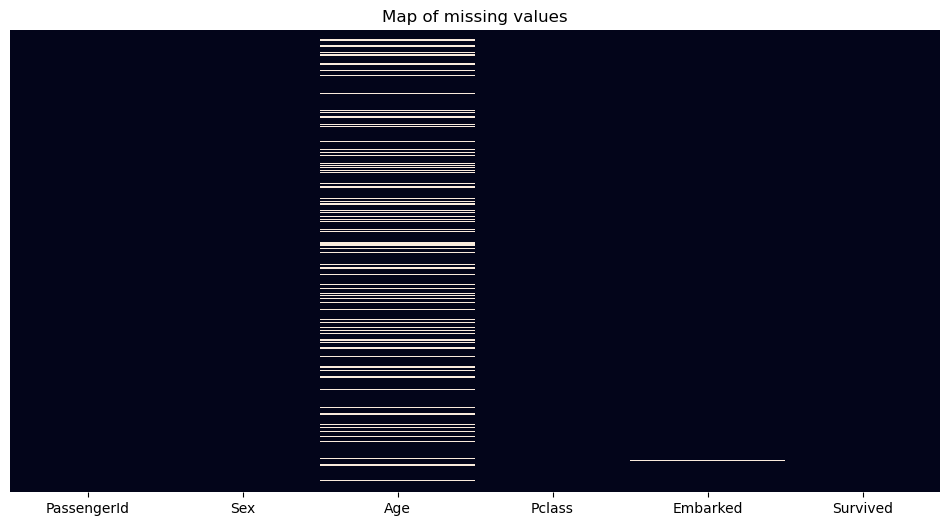

In [161]:
missing_counts = report_missing_values(df_clean,  top_n=None, show_heatmap=True)

## 3.3 Analisi del Target

In [162]:
# distribuzione complessiva
class_counts = df_clean['Survived'].value_counts()
class_pct    = df_clean['Survived'].value_counts(normalize=True).round(3) * 100
print(class_counts)
print(class_pct)

Survived
0    549
1    342
Name: count, dtype: int64
Survived
0    61.6
1    38.4
Name: proportion, dtype: float64


Quindi il dataset non è perfettamente bilanciato (≈ 62 / 38).

Se dividessimo i dati senza stratificare, un semplice estrazione casuale potrebbe – per “sfortuna” – consegnarci un test-set con, ad esempio, l’80 % di classe 0; il modello sembrerebbe “bravissimo” indovinando quasi tutti gli 0, ma la misura non rifletterebbe la realtà.

--> Userò stratify per questo motivo.

## 3.4 Distribuzione delle Feature Numeriche

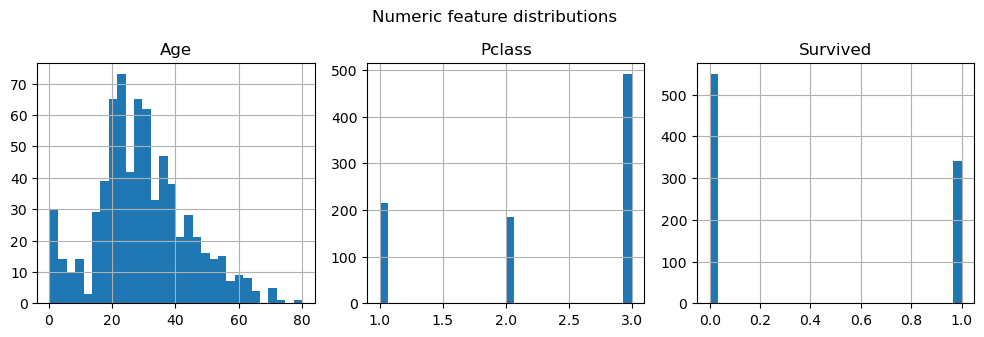

In [163]:
num_cols = df_clean.select_dtypes(include="number").columns.drop(["PassengerId"])
df_clean[num_cols].hist(figsize=(10,6), bins=30, layout=(2,3))
plt.suptitle("Numeric feature distributions")
plt.tight_layout()

## 3.5 Correlazione tra variabili numeriche

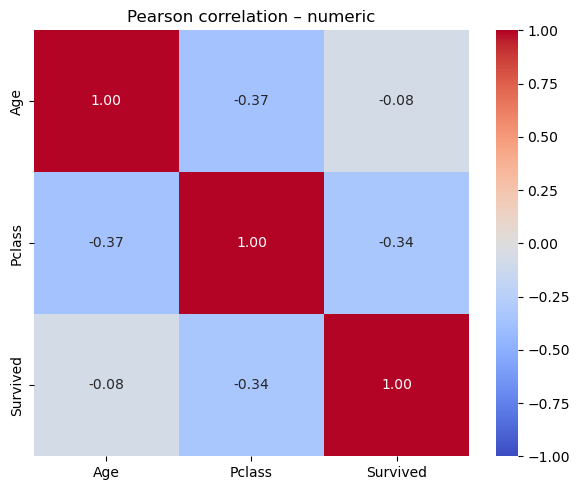

In [164]:
corr_matrix = df_clean[num_cols].corr()
plt.figure(figsize=(6,5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Pearson correlation – numeric"); plt.tight_layout()

Dalla matrice di correlazione emerge che la feature Age ha una correlazione quasi nulla rispetto alla nostra colonna target. Potrei valutare di rimuoverla.

# 4.0 Split dei Dati

In [165]:
from sklearn.model_selection import train_test_split

# Separo target e features

y = df_clean['Survived'] # target
X = df_clean.drop(columns=['Survived', 'PassengerId'])  # drop PassengerId (non predittiva)

# Train-test split (75% train, 25% test) ----------------------------------
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, 
    y, 
    test_size=0.25, 
    random_state=SEED, 
    stratify=y
)

# Train-Validation split (75% train, 25% validation) ----------------------------------
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, 
    y_train_full, 
    test_size=0.25, 
    random_state=SEED, 
    stratify=y_train_full
)

print("X_train: ", X_train.shape)
print("X_val  : ", X_val.shape)
print("X_test : ", X_test.shape)
print("y_train: ", y_train.shape)
print("y_val  : ", y_val.shape)
print("y_test : ", y_test.shape)

X_train:  (501, 4)
X_val  :  (167, 4)
X_test :  (223, 4)
y_train:  (501,)
y_val  :  (167,)
y_test :  (223,)


In [166]:
def class_balance(label, name):
    pct = label.value_counts(normalize=True).round(3) * 100
    return f"{name:<6} 0 → {pct[0]:>5.1f}% | 1 → {pct[1]:>5.1f}%"

print(class_balance(y_train, "train"))
print(class_balance(y_val,   "valid"))
print(class_balance(y_test,  "test "))

train  0 →  61.7% | 1 →  38.3%
valid  0 →  61.7% | 1 →  38.3%
test   0 →  61.4% | 1 →  38.6%


## 4.1 Gestione delle Missing Values

Missing values per column:
Age         94
Embarked     2
dtype: int64 



Age         18.762475
Embarked     0.399202
Sex          0.000000
Pclass       0.000000
dtype: float64

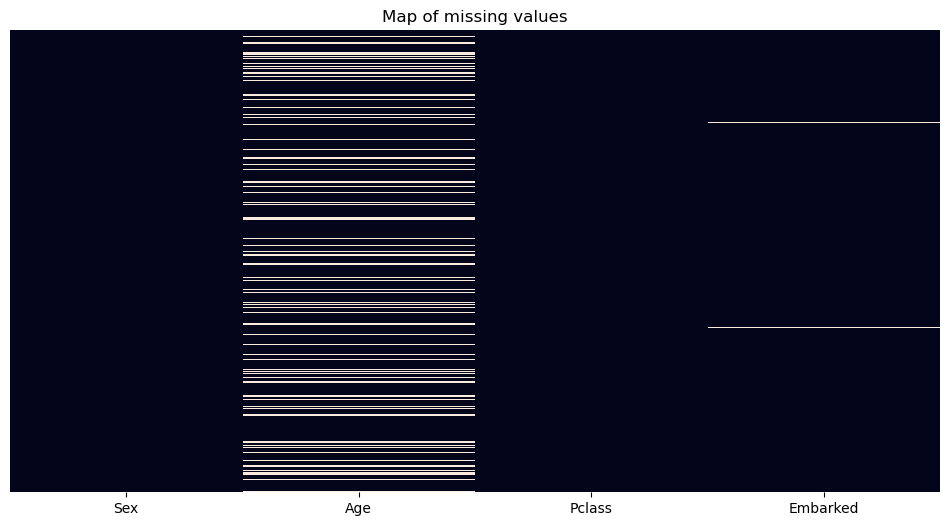

In [167]:
missing_counts = report_missing_values(X_train,  top_n=None, show_heatmap=True)

Mediana Età per (Pclass, Sex) Sex     female  male
Pclass              
1         35.0  42.0
2         28.5  31.0
3         23.0  25.5


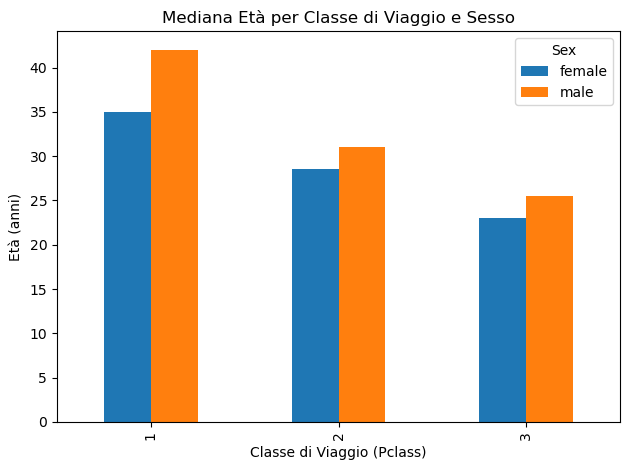

In [168]:
import pandas as pd
import matplotlib.pyplot as plt

# Calcola mediana Age stratificata per Pclass e Sex
group_medians = (
    X_train.groupby(['Pclass', 'Sex'])['Age']
      .median()
      .unstack()
      .round(1)  # round for nicer display
)

print("Mediana Età per (Pclass, Sex)", group_medians)

# Plot
ax = group_medians.plot(kind='bar')
ax.set_title('Mediana Età per Classe di Viaggio e Sesso')
ax.set_xlabel('Classe di Viaggio (Pclass)')
ax.set_ylabel('Età (anni)')
plt.tight_layout()
plt.show()

Analizzando l'età media dei passeggeri, divisa in base a classe di appartenenza e sesso, emergono differenze socio-demografiche reali: 
Ad esempio l'età media delle donne di 1ª classe > uomini di 3ª. Inoltre calcolarla su gruppi più piccoli mantiene la robustezza ma preserva differenze reali. 

#### 4.1.1 Test rapido

In [169]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# ---------------------------------------------------------------------------
# Helper functions
# ---------------------------------------------------------------------------

def build_pipeline(include_age: bool = True, include_embarked: bool = True) -> Pipeline:
    """Restituisce una pipeline di pre-elaborazione + regressione logistica.

    * Utilizza l'imputazione mediana per le caratteristiche numeriche;
    * Utilizza l'imputazione più frequente + One-Hot (handle_unknown=‘ignore’) per le categorie;
    * Scala le caratteristiche numeriche in modo che i coefficienti LR siano più comparabili.
    """
    
    numeric_features = ["Pclass"]
    categorical_features = ["Sex"]

    if include_age:
        numeric_features.append("Age")
    if include_embarked:
        categorical_features.append("Embarked")

    numeric_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]
    )

    categorical_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]
    )

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_features),
            ("cat", categorical_transformer, categorical_features),
        ]
    )

    model = Pipeline(
        steps=[
            ("preprocess", preprocessor),
            ("classifier", LogisticRegression(max_iter=1000, random_state=SEED)),
        ]
    )

    return model


def run_experiment(
    name: str,
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_val: pd.DataFrame,
    y_val: pd.Series,
    include_age: bool = True,
    include_embarked: bool = True,
    drop_na: bool = False,
):
    """Fit + evaluate a pipeline and return metrics + sample sizes."""
    if drop_na:
        keep_idx = X_train.dropna(subset=["Age", "Embarked"]).index
        X_train = X_train.loc[keep_idx]
        y_train = y_train.loc[keep_idx]

        keep_idx = X_val.dropna(subset=["Age", "Embarked"]).index
        X_val = X_val.loc[keep_idx]
        y_val = y_val.loc[keep_idx]

    pipe = build_pipeline(include_age=include_age, include_embarked=include_embarked)
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_val)

    acc = accuracy_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)

    return (name, acc, f1, len(X_train), len(X_val))


# ---------------------------------------------------------------------------
# Experiments (A, B, C) mirroring the original rapid tests
# ---------------------------------------------------------------------------

results = []

# A) Drop the problematic columns entirely
cols_A = X_train.columns.difference(["Age", "Embarked"])
results.append(
    run_experiment(
        "A_drop_cols",
        X_train[cols_A],
        y_train,
        X_val[cols_A],
        y_val,
        include_age=False,
        include_embarked=False,
    )
)

# B) Drop rows with missing Age or Embarked
results.append(
    run_experiment(
        "B_drop_rows",
        X_train,
        y_train,
        X_val,
        y_val,
        include_age=True,
        include_embarked=True,
        drop_na=True,
    )
)

# C) Imputation handled inside the pipeline (recommended)
results.append(
    run_experiment(
        "C_impute",
        X_train,
        y_train,
        X_val,
        y_val,
        include_age=True,
        include_embarked=True,
        drop_na=False,
    )
)

# Pretty‑print the outcomes
for name, acc, f1, n_tr, n_val in results:
    print(f"{name:12s} | acc = {acc:.3f} • f1 = {f1:.3f}   (n_tr = {n_tr}, n_val = {n_val})")


A_drop_cols  | acc = 0.766 • f1 = 0.655   (n_tr = 501, n_val = 167)
B_drop_rows  | acc = 0.800 • f1 = 0.742   (n_tr = 405, n_val = 125)
C_impute     | acc = 0.784 • f1 = 0.690   (n_tr = 501, n_val = 167)


### 4.1.3 Risultati

In seguito a questo esito, ho deciso che utilizzerò il test B.

## 4.2 Associazione categoriche ⇄ target (χ² / V di Cramer)

In [170]:
import pandas as pd
import numpy as np
import scipy.stats as st

def chi2_cramer(col: pd.Series, target: pd.Series):
    """Restituisce χ², p-value e Cramér V per una variabile categorica vs target."""
    contingency = pd.crosstab(col, target)
    chi2, p, _, _ = st.chi2_contingency(contingency, correction=False)
    n = contingency.values.sum()
    k = min(contingency.shape)
    V = np.sqrt(chi2 / (n * (k - 1)))
    return chi2, p, V

# Esempio solo sul training-set (dopo lo split!)
for feat in ["Sex", "Embarked", "Pclass"]:
    chi2, p, V = chi2_cramer(X_train[feat], y_train)
    print(f"{feat:<8}  χ²={chi2:6.1f}  p={p:.3e}  V={V:.3f}")

Sex       χ²= 165.9  p=5.818e-38  V=0.575
Embarked  χ²=  13.1  p=1.425e-03  V=0.162
Pclass    χ²=  64.1  p=1.220e-14  V=0.358


| Variabile    | p-value | Cramér V  |Classificazione     | Info                                                  |
| ------------ | ------- | ----------|---- | ------------------------------------------------------------------- |
| **Sex**      | ≪ 0.05  | **0.57** |forte | Informazione cruciale: Nel titanic si salvarono più donne                                  |
| **Pclass**   | ≪ 0.05  | 0.35 |moderata  | Utile; La priorità venne data alla 1a classe                             |
| **Embarked** | 0.00014 | 0.16 |debole    | Segnale minimale, da valutare. |


## 4.3 Preparazione dei dati prima di applicarli al modello

In [171]:
def drop_nan_rows(df: pd.DataFrame, y: pd.Series) -> tuple[pd.DataFrame, pd.Series]:
    mask = ~df[["Age", "Embarked"]].isna().any(axis=1)
    return df.loc[mask].copy(), y.loc[mask]

X_train, y_train = drop_nan_rows(X_train, y_train)
X_val,   y_val   = drop_nan_rows(X_val,   y_val)
X_test,  y_test  = drop_nan_rows(X_test,  y_test)

print(f"Dropped rows → train {len(y_train)}, val {len(y_val)}, test {len(y_test)}")

Dropped rows → train 405, val 125, test 182


In [172]:
X_train

,Sex,Age,Pclass,Embarked
81,male,29.0,3,S
173,male,21.0,3,S
664,male,20.0,3,S
751,male,6.0,3,S
208,female,16.0,3,Q
...,...,...,...,...
188,male,40.0,3,Q
212,male,22.0,3,S
339,male,45.0,1,S
156,female,16.0,3,Q


In [173]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

# ------------------------------------------------------------------
# 1) Preparo il OneHotEncoder
# ------------------------------------------------------------------
cat_cols = ["Sex", "Embarked"]

ohe = OneHotEncoder(
    handle_unknown="ignore",   
    sparse_output=False,       
    dtype="int8"               
)

ohe.fit(X_train[cat_cols])     # <<-- solo TRAIN, niente leakage!

def encode_with_ohe(df: pd.DataFrame) -> pd.DataFrame:
    """Ritorna un DataFrame con le variabili categoriche una-hot-encodate
    e le numeriche intatte, mantenendo l’indice originale."""
    df_num = df.drop(columns=cat_cols)  # tutte le feature NON categoriche
    encoded = ohe.transform(df[cat_cols])

    # ricava nomi colonne (es. Sex_male, Embarked_S, …) dalla versione 1.2+
    new_cols = ohe.get_feature_names_out(cat_cols)

    df_cat = pd.DataFrame(encoded, columns=new_cols, index=df.index)
    return pd.concat([df_num, df_cat], axis=1)

# ------------------------------------------------------------------
# 2) Applico l’encoder a tutti i set (train, validation, test)
# ------------------------------------------------------------------
X_train_enc = encode_with_ohe(X_train)
X_val_enc   = encode_with_ohe(X_val)
X_test_enc  = encode_with_ohe(X_test)

print(X_train_enc.columns.tolist())


['Age', 'Pclass', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S']


In [174]:
X_train_enc

,Age,Pclass,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
81,29.0,3,0,1,0,0,1
173,21.0,3,0,1,0,0,1
664,20.0,3,0,1,0,0,1
751,6.0,3,0,1,0,0,1
208,16.0,3,1,0,0,1,0
...,...,...,...,...,...,...,...
188,40.0,3,0,1,0,1,0
212,22.0,3,0,1,0,0,1
339,45.0,1,0,1,0,0,1
156,16.0,3,1,0,0,1,0


# 5.0 Decision Tree

## 5.1 Preparazione del modello

In [175]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, GridSearchCV
from sklearn.metrics import make_scorer, f1_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
f1_scorer = make_scorer(f1_score)

# ------------------------------------------------------------------
# 1) ricerca grossolana con RandomizedSearchCV
# ------------------------------------------------------------------
param_dist = {
    "max_depth":        [None] + list(np.arange(2, 51)),     # 2…50
    "min_samples_leaf": np.arange(1, 51),                    # 1…50
    "max_features":     [None, "sqrt", "log2"]
}

rnd_search = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(
        random_state=SEED,
        class_weight="balanced"
    ),
    param_distributions=param_dist,
    n_iter=100,                  # 100 campioni casuali >> 3*4*5 = 60 del tuo grid originale
    scoring=f1_scorer,
    n_jobs=-1,
    cv=cv,
    random_state=SEED
).fit(X_train_enc, y_train)

best_params = rnd_search.best_params_
best_f1     = rnd_search.best_score_
print(f"[1] RandomizedSearch  → best F1={best_f1:.3f}  params={best_params}")

# ------------------------------------------------------------------
# 2) se un iperparametro cade sul bordo, raffinamento locale con GridSearchCV
# ------------------------------------------------------------------
def around(x: int, width: int = 4, low: int = 1) -> list[int]:
    """Restituisce [x-w, …, x, …, x+w] entro i limiti."""
    return [k for k in range(x - width, x + width + 1) if k >= low]

leaf_star = best_params["min_samples_leaf"]
depth_star = best_params["max_depth"] if best_params["max_depth"] else 0  # None → 0 fittizio

# controlla se siamo ai bordi dell’intervallo iniziale
border_leaf  = leaf_star in (param_dist["min_samples_leaf"][0], param_dist["min_samples_leaf"][-1])
border_depth = depth_star in (0, param_dist["max_depth"][-1])

if border_leaf or border_depth:
    grid = {
        "max_depth":        [None] if depth_star == 0 else around(depth_star, width=3, low=2),
        "min_samples_leaf": around(leaf_star, width=3, low=1),
        "max_features":     [best_params["max_features"]],  # già ben determinato
    }

    grid_search = GridSearchCV(
        estimator=DecisionTreeClassifier(
            random_state=SEED,
            class_weight="balanced"
        ),
        param_grid=grid,
        scoring=f1_scorer,
        cv=cv,
        n_jobs=-1
    ).fit(X_train_enc, y_train)

    best_params = grid_search.best_params_
    best_f1     = grid_search.best_score_
    print(f"[2] GridSearch      → best F1={best_f1:.3f}  params={best_params}")

# ------------------------------------------------------------------
# 3) addestramento finale sul train completo e valutazione sul validation
# ------------------------------------------------------------------
dt_best = DecisionTreeClassifier(
    random_state=SEED,
    class_weight="balanced",
    **best_params
).fit(X_train_enc, y_train)

val_f1  = f1_score(y_val, dt_best.predict(X_val_enc))
val_acc = accuracy_score(y_val, dt_best.predict(X_val_enc))
print(f"[VAL] acc={val_acc:.3f}  F1={val_f1:.3f}  con params={best_params}")


[1] RandomizedSearch  → best F1=0.765  params={'min_samples_leaf': 11, 'max_features': 'sqrt', 'max_depth': 21}
[VAL] acc=0.808  F1=0.755  con params={'min_samples_leaf': 11, 'max_features': 'sqrt', 'max_depth': 21}


Questo è il miglio modello:

|modello|acc|f1|
|-------|---|--|
|DT     |0.808|0.755|

In [176]:
# fit su train + val con i migliori hyper-parametri
X_fin = pd.concat([X_train_enc, X_val_enc], axis=0)
y_fin = pd.concat([y_train, y_val], axis=0)

dt_final = DecisionTreeClassifier(
    random_state=SEED,
    class_weight="balanced",
    **best_params
).fit(X_fin, y_fin)

y_test_pred = dt_final.predict(X_test_enc)
print(f"TEST  –  acc {accuracy_score(y_test, y_test_pred):.3f} "
      f"F1 {f1_score(y_test, y_test_pred):.3f}")

TEST  –  acc 0.764 F1 0.699


In [177]:
dt_final.get_params()

{'ccp_alpha': 0.0,
 'class_weight': 'balanced',
 'criterion': 'gini',
 'max_depth': 21,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 11,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': 0,
 'splitter': 'best'}

Per essere un singolo albero, su un dataset cosi limitato, il risultato è abbastanza decente.

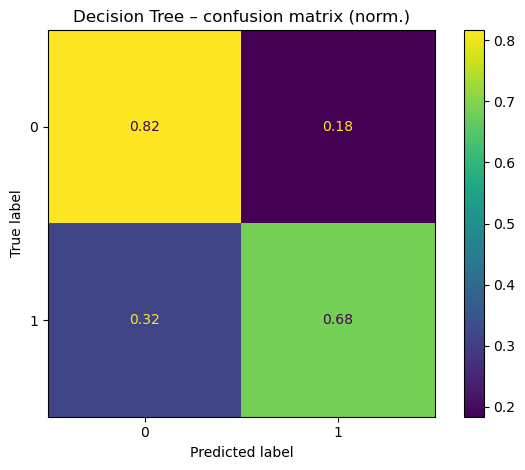

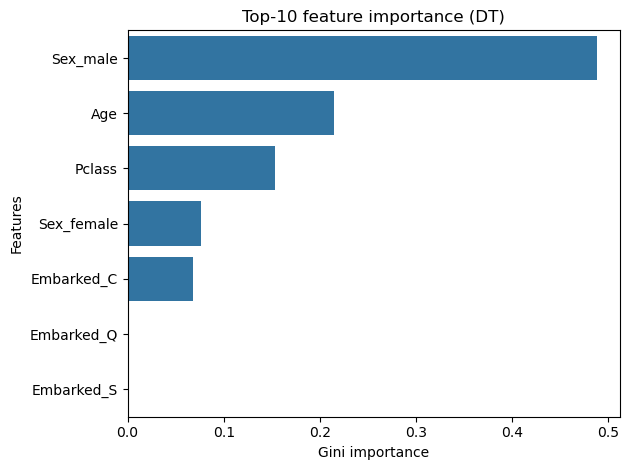

In [178]:
from sklearn.metrics import ConfusionMatrixDisplay

# a) Confusion matrix
ConfusionMatrixDisplay.from_estimator(dt_final, X_test_enc, y_test, normalize='true')
plt.title("Decision Tree – confusion matrix (norm.)")
plt.tight_layout() 
plt.show()

# b) Feature importance
imp = (pd.Series(dt_final.feature_importances_, index=X_fin.columns)
         .sort_values(ascending=False))
sns.barplot(x=imp.head(10), y=imp.head(10).index)
plt.title("Top-10 feature importance (DT)")
plt.xlabel("Gini importance") 
plt.ylabel("Features") 
plt.tight_layout() 
plt.show()

Tuttavia, il modello non performa bene nella predizione dei sopravvissuti. 

## 5.2 Plot dell'Albero

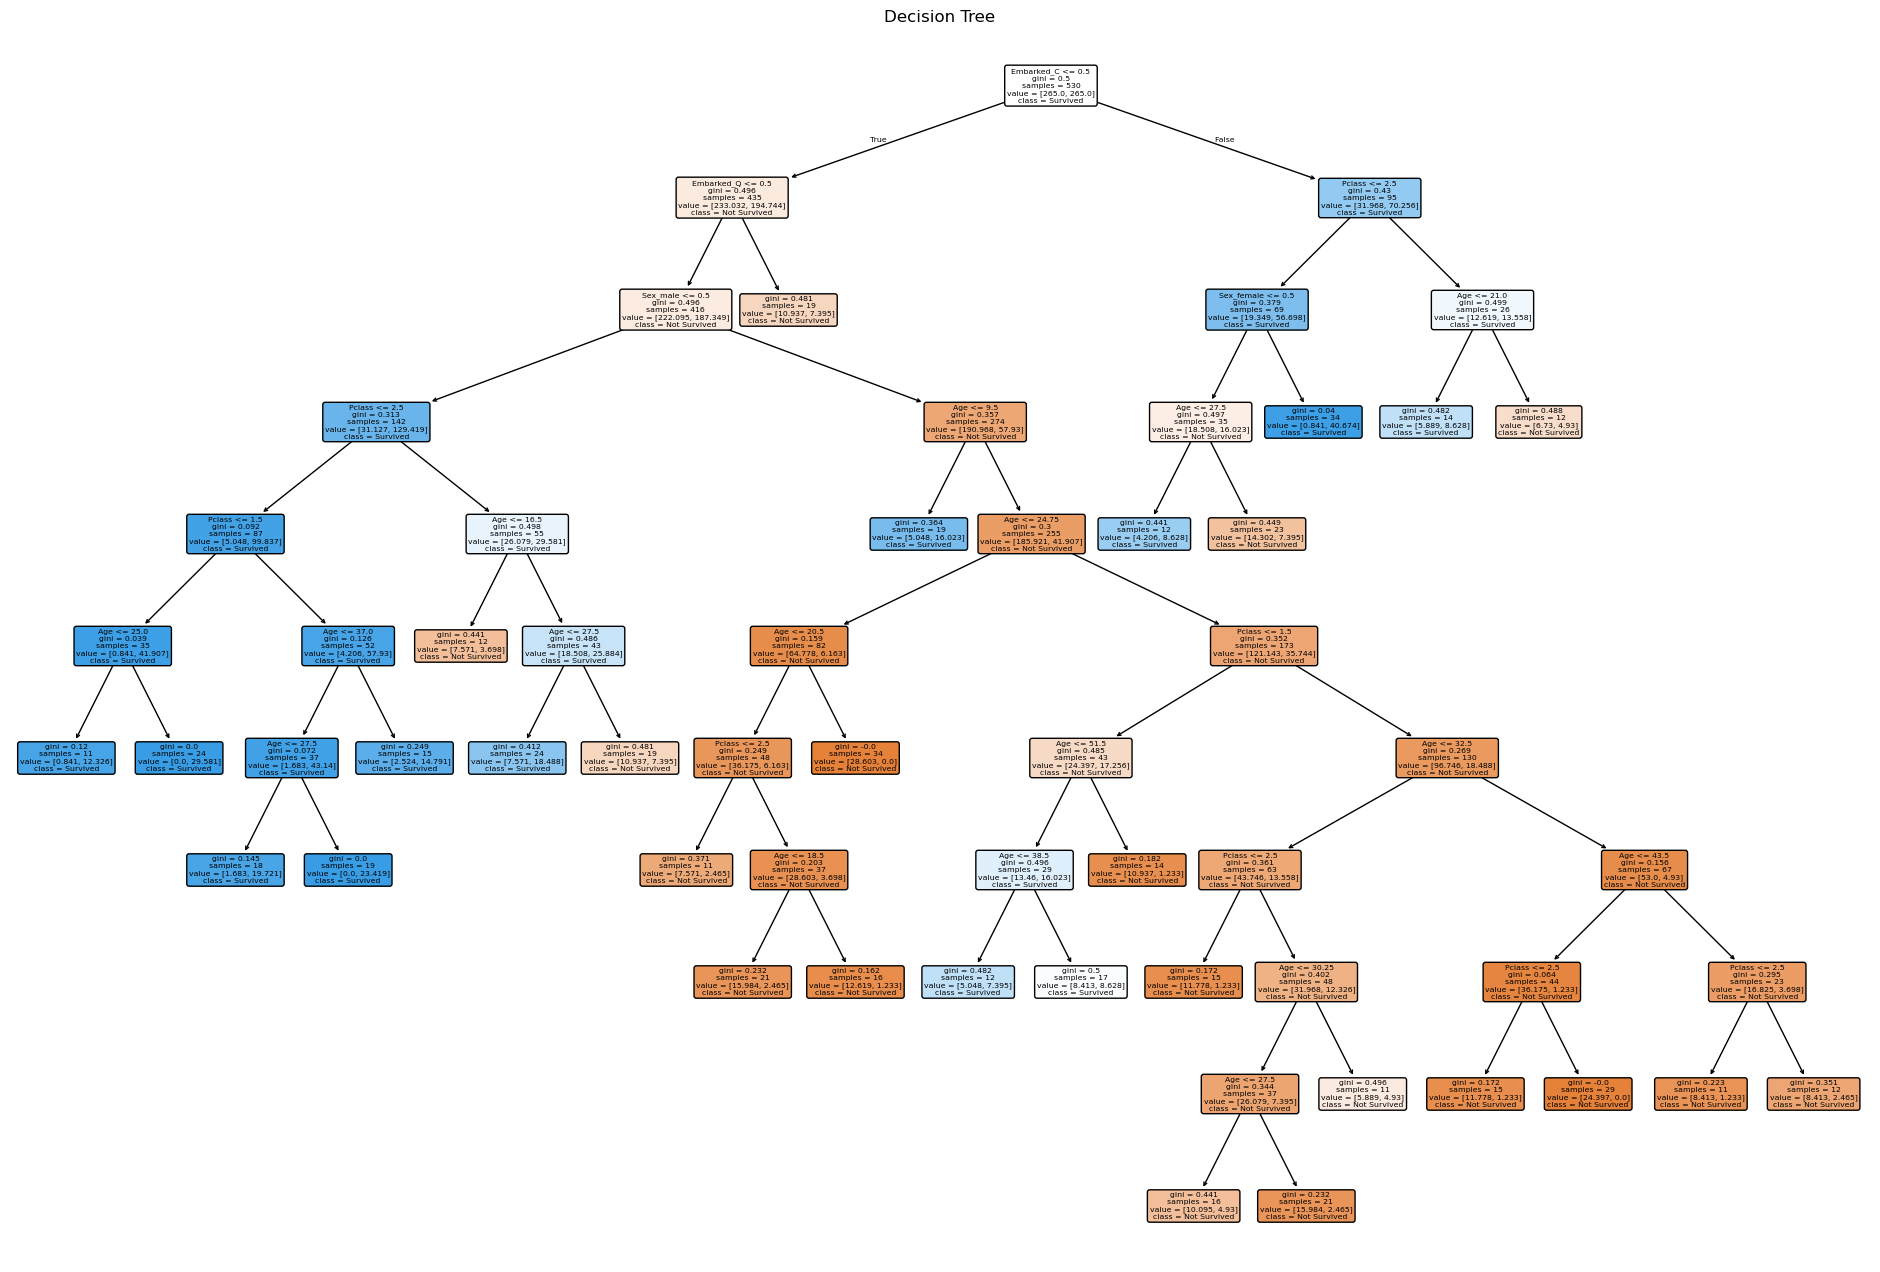

In [179]:
from sklearn.tree import plot_tree

# Plot Albero
plt.figure(figsize=(24, 16))
plot_tree(dt_final,
          feature_names=X_test_enc.columns,
          class_names=['Not Survived', 'Survived'],
          filled=True,
          rounded=True)
plt.title('Decision Tree')
plt.savefig("DT5")
plt.show()


- Nodi colorati: più chiara è la tonalità, più purezza/impurity bassa (cioè i campioni appartengono quasi tutti alla stessa classe).
- Valori nei nodi:

    - gini = impurità di Gini dopo lo split

    - samples = numero di osservazioni nel nodo

    - value = conteggio [non sopravvissuti, sopravvissuti]

## 6.3 Permutation Importance test

Scambia a caso i valori di ogni feature nel test-set: se il modello peggiora molto significa che quella variabile era davvero utile; se l’accuratezza quasi non cambia l’importanza è bassa. 

A differenza della Gini importance non dipende da quante volte una feature è stata scelta per lo split ed è meno soggetta a bias.

,perm_importance
Sex_male,0.111722
Pclass,0.100916
Age,0.047985
Embarked_C,0.036996
Sex_female,0.023443
Embarked_Q,0.003663
Embarked_S,0.000000


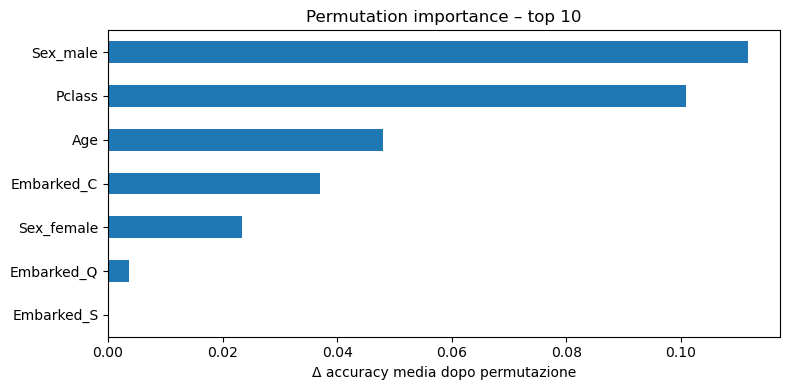

In [180]:
# ----------------  PERMUTATION IMPORTANCE  ----------------
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# 1) calcolo
perm = permutation_importance(
    estimator      = dt_final,
    X              = X_test_enc,
    y              = y_test,
    n_repeats      = 30,      # >10 = stima più stabile
    random_state   = SEED,
    n_jobs         = -1
)

# 2) pandas Series ordinata
imp_series = pd.Series(
    perm.importances_mean,
    index=X_test_enc.columns
).sort_values(ascending=False)

display(imp_series.head(10).to_frame("perm_importance"))

# 3) grafico
plt.figure(figsize=(8, 4))
imp_series.head(10).plot(kind="barh")
plt.gca().invert_yaxis()           # feature più importante in alto
plt.title("Permutation importance – top 10")
plt.xlabel("Δ accuracy media dopo permutazione")
plt.tight_layout()
plt.show()

# 7.0 Conclusioni

## Grazie!

Visita il mio [blog personale](https://stefanonocco.it/) o colleghiamoci su:  
- [LinkedIn](https://www.linkedin.com/in/stefanonocco/)  
- [Instagram](https://www.instagram.com/steno.py/)  

***Stefano Nocco***
